<a href="https://colab.research.google.com/github/kvikaee/data-analysis-python/blob/main/7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

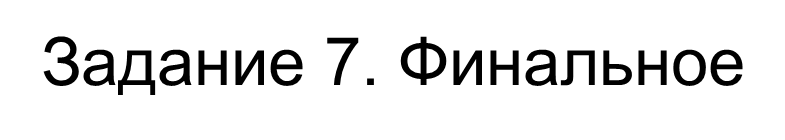

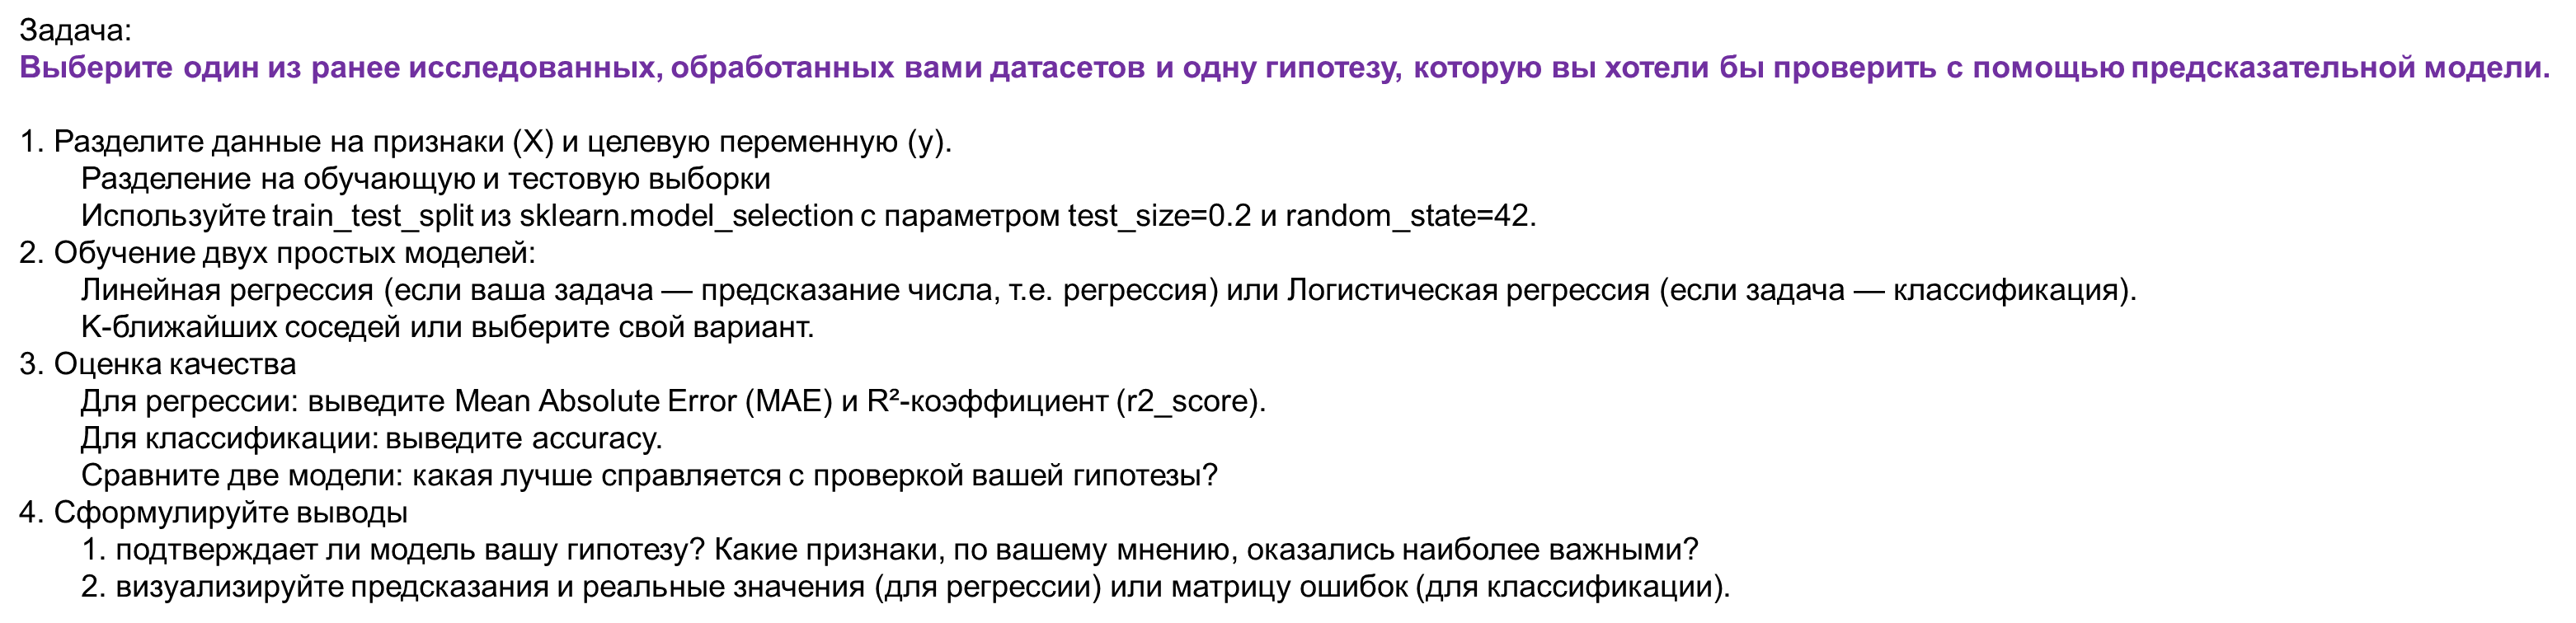

**Гипотеза**: итоговый показатель успеваемости Performance Index можно достаточно хорошо предсказывать по учебной нагрузке и контекстным факторам:
*Hours Studied*, *Previous Scores*, *Sleep Hours*, *Sample Question Papers Practiced*, *Extracurricular Activities*.
Ожидается, что больше часов учёбы и практики, более высокие прошлые оценки и наличие внеклассной активности связаны с более высоким *Performance Index*.

[Ссылка на датасет](https://www.kaggle.com/datasets/neurocipher/student-performance)

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [ ]:
df = pd.read_csv('StudentPerformance.csv')

# Закодируем категориальный признак: Yes/No -> 1/0
df_model = df.copy()
df_model['Extracurricular Activities'] = df_model['Extracurricular Activities'].map({'Yes': 1, 'No': 0})

# Признаки (x) и цель (y)
feature_cols = [
    'Hours Studied',
    'Previous Scores',
    'Sleep Hours',
    'Sample Question Papers Practiced',
    'Extracurricular Activities'
]

target_col = 'Performance Index'

X = df_model[feature_cols]
y = df_model[target_col]

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape


((8000, 5), (2000, 5))

In [ ]:
# Модель 1: Линейная регрессия
linreg_model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('reg', LinearRegression())
])

# Модель 2: K-ближайших соседей (регрессия)
knn_model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('reg', KNeighborsRegressor(n_neighbors=5))
])

# Обучение
linreg_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

# Предсказания
y_pred_linreg = linreg_model.predict(X_test)
y_pred_knn = knn_model.predict(X_test)


In [ ]:
def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return mae, r2

mae_lin, r2_lin = evaluate_regression(y_test, y_pred_linreg)
mae_knn, r2_knn = evaluate_regression(y_test, y_pred_knn)

results_df = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN (k=5)'],
    'MAE':   [mae_lin, mae_knn],
    'R2':    [r2_lin, r2_knn]
})

results_df


,Model,MAE,R2
0,Linear Regression,1.611121,0.988983
1,KNN (k=5),2.358100,0.976894


In [ ]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=['Linear Regression', 'KNN (k=5)'],
    horizontal_spacing=0.12
)

# Линия y = x (идеальные предсказания)
min_val = min(y_test.min(), y_pred_linreg.min(), y_pred_knn.min())
max_val = max(y_test.max(), y_pred_linreg.max(), y_pred_knn.max())

line_x = np.linspace(min_val, max_val, 100)

# 1. Linear Regression
fig.add_trace(
    go.Scatter(
        x=y_test,
        y=y_pred_linreg,
        mode='markers',
        marker=dict(color='steelblue', opacity=0.6),
        name='LinReg'
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=line_x,
        y=line_x,
        mode='lines',
        line=dict(color='red', dash='dash'),
        showlegend=False
    ),
    row=1, col=1
)

# 2. KNN
fig.add_trace(
    go.Scatter(
        x=y_test,
        y=y_pred_knn,
        mode='markers',
        marker=dict(color='seagreen', opacity=0.6),
        name='KNN'
    ),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(
        x=line_x,
        y=line_x,
        mode='lines',
        line=dict(color='red', dash='dash'),
        showlegend=False
    ),
    row=1, col=2
)

fig.update_xaxes(title_text='Фактический Performance Index', row=1, col=1)
fig.update_yaxes(title_text='Предсказанный Performance Index', row=1, col=1)

fig.update_xaxes(title_text='Фактический Performance Index', row=1, col=2)
fig.update_yaxes(title_text='Предсказанный Performance Index', row=1, col=2)

fig.update_layout(
    height=500,
    width=1000,
    title_text='Сравнение реальных и предсказанных значений Performance Index'
)

fig.show()


### 3. Оценка качества моделей

По результатам тестовой выборки:

- **Linear Regression**  
  - MAE ≈ **1.61**  
  - R² ≈ **0.989**
- **KNN (k = 5)**  
  - MAE ≈ **2.36**  
  - R² ≈ **0.977**

То есть **линейная регрессия даёт меньшую среднюю абсолютную ошибку и более высокий R²**, чем KNN. На scatter-графиках это видно по тому, что синие точки (Linear Regression) лежат ближе к диагонали `y = x`, чем зелёные точки KNN.  
**Вывод:** с точки зрения и MAE, и R², **линейная регрессия лучше справляется с проверкой гипотезы** о том, что Performance Index можно предсказывать по выбранным признакам.

### 4. Выводы

**1. Подтверждает ли модель гипотезу и какие признаки важны**

Полученные метрики (R² почти 0.99 для линейной регрессии) означают, что модель объясняет практически всю вариацию итогового показателя *Performance Index*, опираясь только на выбранные факторы. Это хорошо поддерживает гипотезу:  
*успеваемость студента действительно тесно связана с количеством часов учёбы, предыдущими оценками, количеством прорешанных примерочных заданий, сном и внеклассной активностью.*

По смыслу и по структуре признаков наиболее важными можно считать:

- *Previous Scores* - отражают уже накопленный уровень знаний и дают сильный базовый вклад в итоговый индекс.  
- *Hours Studied* и *Sample Question Papers Practiced* - характеризуют текущие учебные усилия (время подготовки и объём практики) и напрямую связаны с ростом *Performance Index*.  
- *Sleep Hours* и *Extracurricular Activities* влияют слабее и, скорее, выступают как дополнительные факторы, которые немного корректируют итоговый результат.

**2. Визуализация предсказаний и реальных значений**

На построенных графиках «фактический vs предсказанный Performance Index»:

- для **линейной регрессии** точки плотно ложатся вдоль красной диагонали, отклонения небольшие - модель даёт стабильные и почти несмещённые предсказания по всему диапазону значений;
- для **KNN** разброс вокруг диагонали больше, особенно в середине диапазона, что согласуется с более высоким MAE и чуть меньшим R².

Таким образом, визуализация подтверждает численные метрики: **линейная регрессия даёт более точные и гладкие предсказания**, поэтому именно её можно считать предпочтительной моделью для проверки выбранной гипотезы на этом датасете.